In [1]:
import numpy as np
from trajectory_utils import extract_trajectory_frames, filter_trajectory_frames, compute_trajectory_deltas
from optical_flow_utils import extract_video_frames, compute_optical_flow, aggregate_optical_flow
from common_utils import angular_difference


In [2]:
interval = 30


Number of camera poses read: 817
Number of camera poses left after filtering: 28


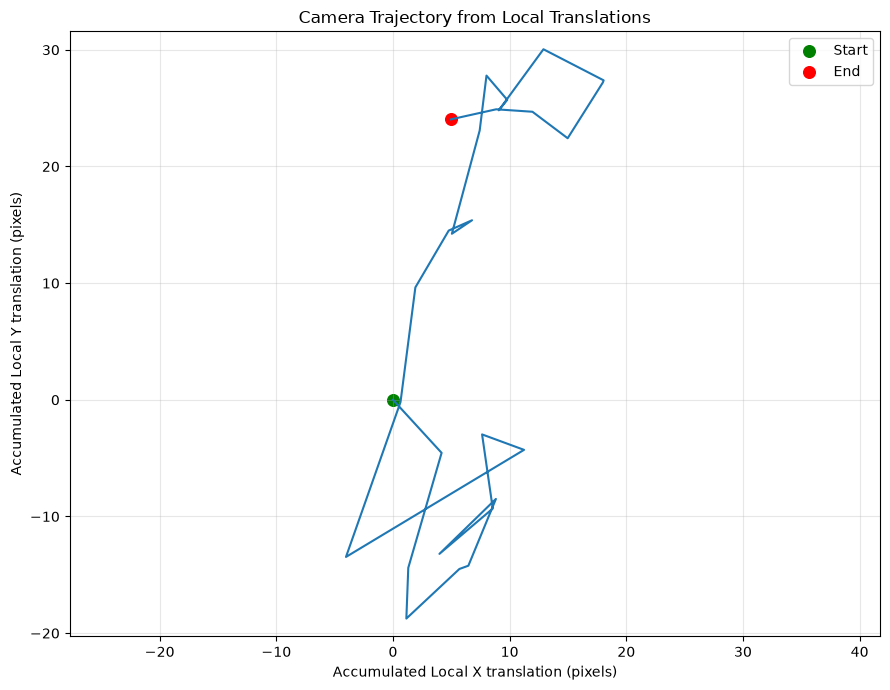

In [3]:
json_file = "p07_left_preop_scope02_traj.json"

poses = extract_trajectory_frames(json_file)
print(f"Number of camera poses read: {len(poses)}")

poses = filter_trajectory_frames(poses, interval)
print(f"Number of camera poses left after filtering: {len(poses)}")

# Calculate local translations in camera view
trajectory_data = compute_trajectory_deltas(poses)

pose_angles = trajectory_data['angles']
dx_local = trajectory_data['dx']
dy_local = trajectory_data['dy']
dz_local = trajectory_data['dz']

# Plot the trajectory using the dx and dy from local_deltas
trajectory_x = np.zeros(len(poses))
trajectory_y = np.zeros(len(poses))
if len(dx_local) > 0:
    trajectory_x[1:] = np.cumsum(dx_local)
    trajectory_y[1:] = np.cumsum(dy_local)

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))
plt.plot(trajectory_x, trajectory_y, linewidth=1.5)
plt.scatter(trajectory_x[0], trajectory_y[0], color="green", s=70, label="Start")
plt.scatter(trajectory_x[-1], trajectory_y[-1], color="red", s=70, label="End")
plt.xlabel("Accumulated Local X translation (pixels)")
plt.ylabel("Accumulated Local Y translation (pixels)")
plt.title("Camera Trajectory from Local Translations")
plt.axis("equal")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [4]:
input_video = "videos/p07_left_preop_scope02.mp4"
video_frames = extract_video_frames(input_video)

print(f"Successfully extracted {len(video_frames)} frames.")

# Run Lucas-Kanade optical flow on all extracted frames
optical_flow_results = compute_optical_flow(video_frames)
print(f"Number of raw optical flow frame-transitions: {len(optical_flow_results)}")

# Aggregate flow into 15-frame chunks to match poses
aggregated_flow = aggregate_optical_flow(optical_flow_results, interval)
num_aggregated = len(aggregated_flow['flow_x'])
print(f"Number of 15-frame aggregated flow intervals: {num_aggregated}")


Reading video: videos/p07_left_preop_scope02.mp4
Successfully extracted 817 frames.
Computing optical flow across 817 frames...
Obtaining circle mask...
Number of raw optical flow frame-transitions: 816
Number of 15-frame aggregated flow intervals: 27


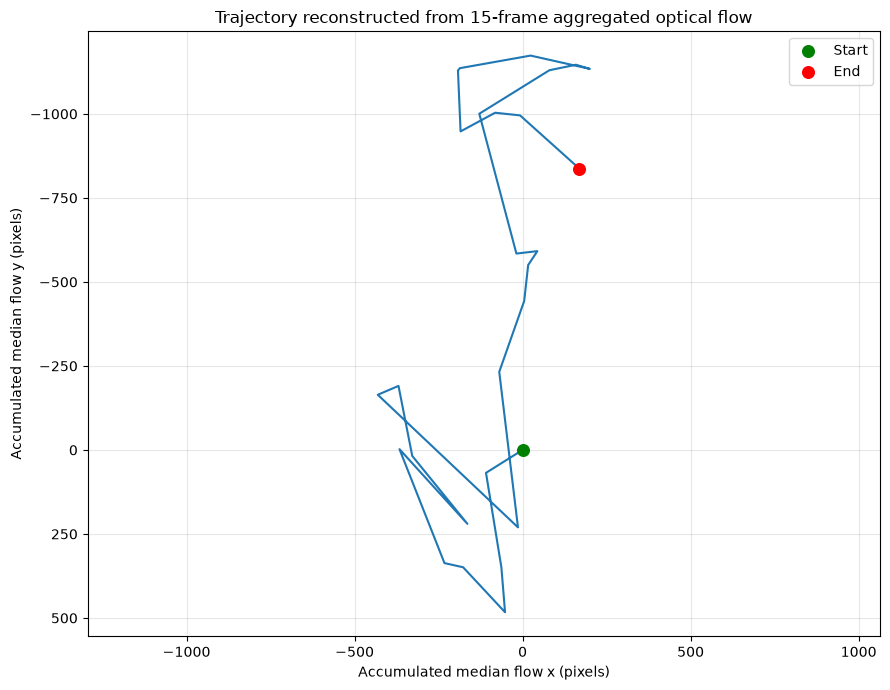

In [5]:
flow_x = aggregated_flow["flow_x"]
flow_y = aggregated_flow["flow_y"]

flow_trajectory = np.zeros((len(flow_x) + 1, 2), dtype=float)
flow_trajectory[1:, 0] = np.cumsum(flow_x)
flow_trajectory[1:, 1] = np.cumsum(flow_y)

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))
plt.plot(flow_trajectory[:, 0], flow_trajectory[:, 1], color="tab:blue", linewidth=1.5)
plt.scatter(flow_trajectory[0, 0], flow_trajectory[0, 1], color="green", s=70, label="Start", zorder=3)
plt.scatter(flow_trajectory[-1, 0], flow_trajectory[-1, 1], color="red", s=70, label="End", zorder=3)
plt.xlabel("Accumulated median flow x (pixels)")
plt.ylabel("Accumulated median flow y (pixels)")
plt.title("Trajectory reconstructed from 15-frame aggregated optical flow")
plt.gca().invert_yaxis() # Invert Y because pixel coordinates go down
plt.axis("equal")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Total transition intervals: 27
Mean Angular Direction Error: 31.05 degrees


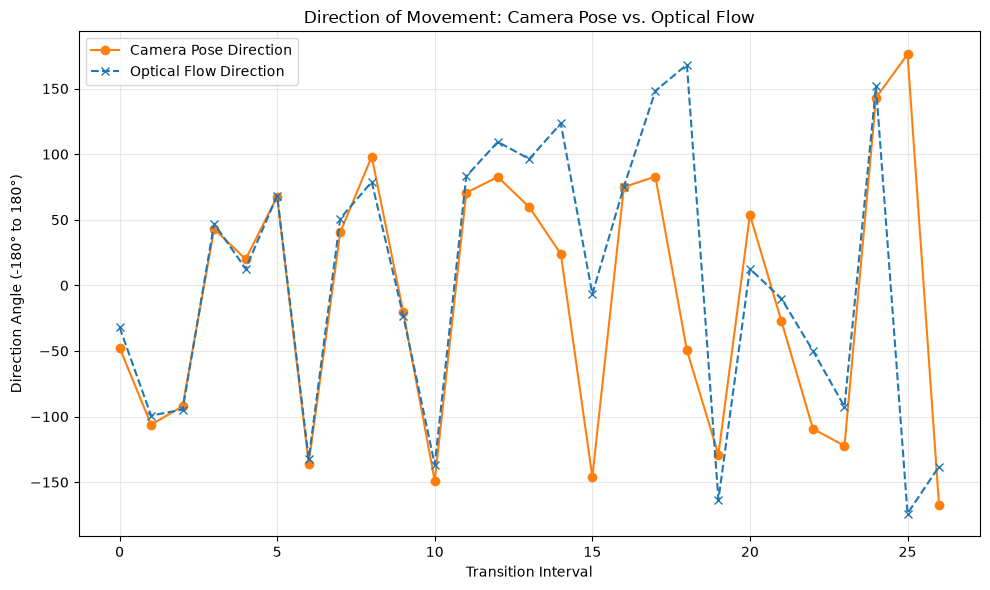

In [6]:
# --- DIRECTIONAL COMPARISON ---
# We compare angles instead of magnitudes because depth scaling breaks magnitude comparisons.

flow_angles = aggregated_flow["angles"]

# Safety check: Ensure pose length matches flow length
min_len = min(len(pose_angles), len(flow_angles))
pose_angles_matched = pose_angles[:min_len]
flow_angles_matched = flow_angles[:min_len]

errors_in_rad = angular_difference(pose_angles_matched, flow_angles_matched)
mean_error_deg = np.degrees(np.mean(errors_in_rad))

print(f"Total transition intervals: {min_len}")
print(f"Mean Angular Direction Error: {mean_error_deg:.2f} degrees")

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(np.degrees(pose_angles_matched), label="Camera Pose Direction", marker='o', linestyle='-', color='tab:orange')
plt.plot(np.degrees(flow_angles_matched), label="Optical Flow Direction", marker='x', linestyle='--', color='tab:blue')
plt.xlabel("Transition Interval")
plt.ylabel("Direction Angle (-180° to 180°)")
plt.title("Direction of Movement: Camera Pose vs. Optical Flow")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


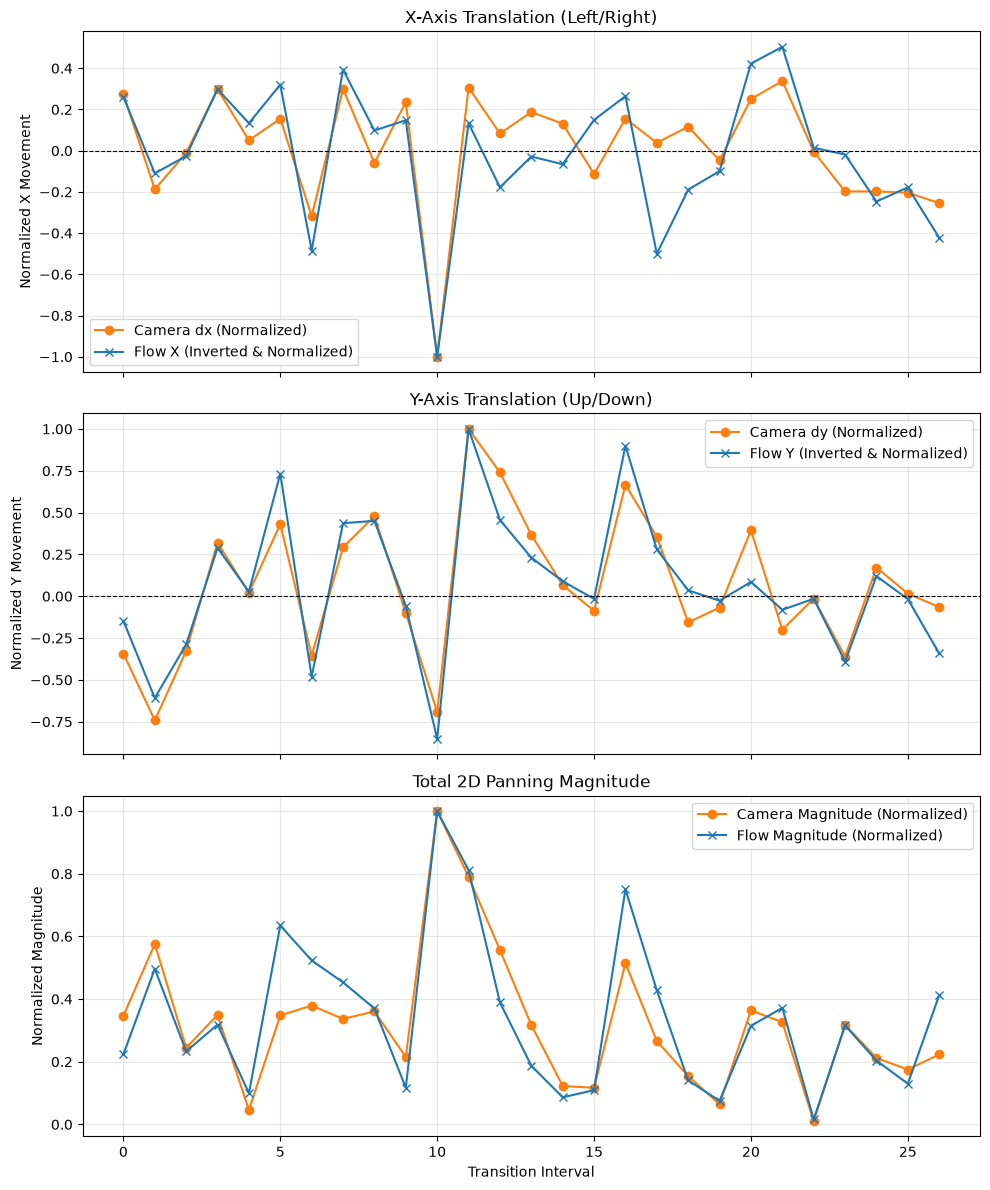

In [7]:
# --- COMPONENT COMPARISON (dx, dy, magnitude) ---
import matplotlib.pyplot as plt
import numpy as np

flow_x = aggregated_flow["flow_x"]
flow_y = aggregated_flow["flow_y"]
pose_magnitudes = trajectory_data["magnitudes"]
flow_magnitudes = aggregated_flow["magnitudes"]

# Safety check: Ensure lengths match
min_len = min(len(dx_local), len(flow_x))
dx_matched = dx_local[:min_len]
dy_matched = dy_local[:min_len]
flow_x_matched = flow_x[:min_len]
flow_y_matched = flow_y[:min_len]
pose_mag_matched = pose_magnitudes[:min_len]
flow_mag_matched = flow_magnitudes[:min_len]

# Note: Optical flow is the inverse of camera egomotion. 
# When the camera moves right (+), the image pixels slide left (-).
# We explicitly invert the flow to match the camera's perspective!
flow_x_aligned = -flow_x_matched
flow_y_aligned = -flow_y_matched

def scale_symmetric(arr):
    """Scales an array from -1 to 1 while preserving the 0-crossing sign."""
    max_val = np.max(np.abs(arr))
    return arr / max_val if max_val != 0 else arr

# We must normalize them to the same scale because camera poses are in metric units (mm) 
# while optical flow is in pixels! We scale them to [-1, 1].
dx_norm = scale_symmetric(dx_matched)
dy_norm = scale_symmetric(dy_matched)
flow_x_norm = scale_symmetric(flow_x_aligned)
flow_y_norm = scale_symmetric(flow_y_aligned)

# Magnitudes are strictly positive, so we just divide by the max to scale to [0, 1]
pose_mag_norm = pose_mag_matched / np.max(pose_mag_matched) if np.max(pose_mag_matched) != 0 else pose_mag_matched
flow_mag_norm = flow_mag_matched / np.max(flow_mag_matched) if np.max(flow_mag_matched) != 0 else flow_mag_matched

# Create a 3-panel plot
fig, axs = plt.subplots(3, 1, figsize=(10, 12), sharex=True)

# 1. Plot X
axs[0].plot(dx_norm, label="Camera dx (Normalized)", marker='o', color='tab:orange')
axs[0].plot(flow_x_norm, label="Flow X (Inverted & Normalized)", marker='x', color='tab:blue')
axs[0].set_ylabel("Normalized X Movement")
axs[0].set_title("X-Axis Translation (Left/Right)")
axs[0].grid(alpha=0.3)
axs[0].legend()
axs[0].axhline(0, color='black', linewidth=0.8, linestyle='--')

# 2. Plot Y
axs[1].plot(dy_norm, label="Camera dy (Normalized)", marker='o', color='tab:orange')
axs[1].plot(flow_y_norm, label="Flow Y (Inverted & Normalized)", marker='x', color='tab:blue')
axs[1].set_ylabel("Normalized Y Movement")
axs[1].set_title("Y-Axis Translation (Up/Down)")
axs[1].grid(alpha=0.3)
axs[1].legend()
axs[1].axhline(0, color='black', linewidth=0.8, linestyle='--')

# 3. Plot Magnitude
axs[2].plot(pose_mag_norm, label="Camera Magnitude (Normalized)", marker='o', color='tab:orange')
axs[2].plot(flow_mag_norm, label="Flow Magnitude (Normalized)", marker='x', color='tab:blue')
axs[2].set_ylabel("Normalized Magnitude")
axs[2].set_title("Total 2D Panning Magnitude")
axs[2].set_xlabel("Transition Interval")
axs[2].grid(alpha=0.3)
axs[2].legend()

plt.tight_layout()
plt.show()


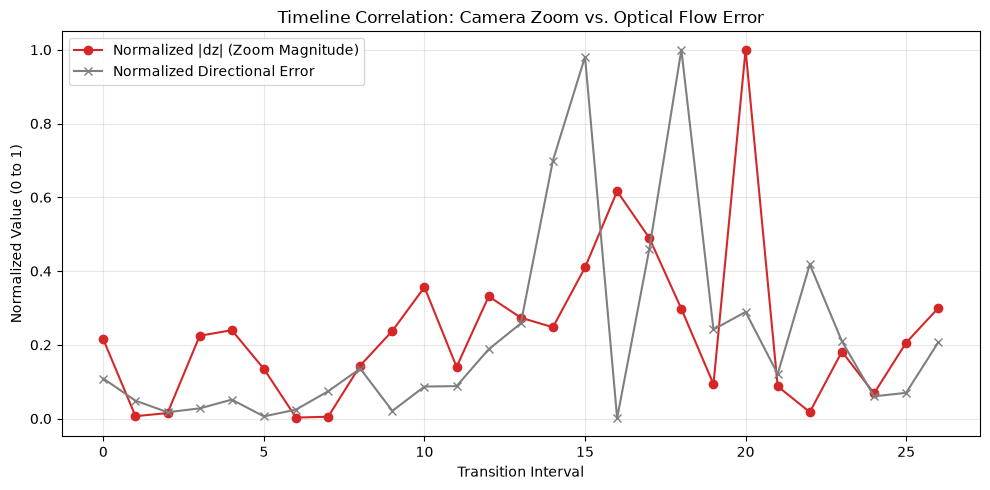

In [8]:
# --- ERROR VS ZOOM OVER TIME ---
import matplotlib.pyplot as plt
import numpy as np

# Extract the absolute Z-translation and ensure lengths match
dz_abs = np.abs(dz_local[:min_len])

# Normalize both arrays to a [0, 1] scale for direct comparison
dz_norm = dz_abs / np.max(dz_abs) if np.max(dz_abs) != 0 else dz_abs
errors_norm = errors_in_rad / np.max(errors_in_rad) if np.max(errors_in_rad) != 0 else errors_in_rad

# Transition intervals are just the sequential indices
intervals = np.arange(len(dz_norm))

plt.figure(figsize=(10, 5))
plt.plot(intervals, dz_norm, label="Normalized |dz| (Zoom Magnitude)", marker='o', color='tab:red')
plt.plot(intervals, errors_norm, label="Normalized Directional Error", marker='x', color='tab:gray')

plt.xlabel("Transition Interval")
plt.ylabel("Normalized Value (0 to 1)")
plt.title("Timeline Correlation: Camera Zoom vs. Optical Flow Error")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
